## Cell 1 — model.py

In [1]:
"""
model.py — Transformer Architecture Skeleton
DA6401 Assignment 3: "Attention Is All You Need"

AUTOGRADER CONTRACT (DO NOT MODIFY SIGNATURES):
  ┌─────────────────────────────────────────────────────────────────┐
  │  scaled_dot_product_attention(Q, K, V, mask) → (out, weights)  │
  │  MultiHeadAttention.forward(q, k, v, mask)   → Tensor          │
  │  PositionalEncoding.forward(x)               → Tensor          │
  │  make_src_mask(src, pad_idx)                 → BoolTensor      │
  │  make_tgt_mask(tgt, pad_idx)                 → BoolTensor      │
  │  Transformer.encode(src, src_mask)           → Tensor          │
  │  Transformer.decode(memory,src_m,tgt,tgt_m)  → Tensor          │
  └─────────────────────────────────────────────────────────────────┘
"""

import copy
import math
from functools import lru_cache
from pathlib import Path
from typing import Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F

_MODULE_DIR = "/kaggle/working"

DEFAULT_CHECKPOINT_FILE_ID = "1rXyhzh_9ozSHLu0uPwi_R7U0Tgqoi73n"
DEFAULT_CHECKPOINT_PATH = "/kaggle/working/checkpoints/best_bleu_checkpoint.pt"
PAD_TOKEN = "<pad>"
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"


@lru_cache(maxsize=1)
def _get_text_inference_assets():
    from dataset import Multi30kDataset

    dataset = Multi30kDataset(split="train")
    return dataset.src_vocab, dataset.tgt_vocab, Multi30kDataset._get_tokenizer("de")


def _checkpoint_candidates() -> list[Path]:
    candidates = [
        DEFAULT_CHECKPOINT_PATH,
        _MODULE_DIR / "checkpoint.pt",
        Path.cwd() / "checkpoints" / "best_bleu_checkpoint.pt",
        Path.cwd() / "checkpoint.pt",
    ]
    unique_candidates: list[Path] = []
    seen = set()
    for path in candidates:
        resolved = path.resolve()
        if resolved not in seen:
            seen.add(resolved)
            unique_candidates.append(path)
    return unique_candidates


def _extract_model_state_dict(checkpoint):
    state_dict = (
        checkpoint.get("model_state_dict", checkpoint)
        if isinstance(checkpoint, dict)
        else checkpoint
    )
    if not isinstance(state_dict, dict):
        return None
    if state_dict and all(str(key).startswith("module.") for key in state_dict):
        state_dict = {str(key)[7:]: value for key, value in state_dict.items()}
    return state_dict

# ══════════════════════════════════════════════════════════════════════
#   STANDALONE ATTENTION FUNCTION
#    Exposed at module level so the autograder can import and test it
#    independently of MultiHeadAttention.
# ══════════════════════════════════════════════════════════════════════


def scaled_dot_product_attention(
    Q: torch.Tensor,
    K: torch.Tensor,
    V: torch.Tensor,
    mask: Optional[torch.Tensor] = None,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Compute Scaled Dot-Product Attention.

        Attention(Q, K, V) = softmax( Q·Kᵀ / √dₖ ) · V

    Args:
        Q    : Query tensor,  shape (..., seq_q, d_k)
        K    : Key tensor,    shape (..., seq_k, d_k)
        V    : Value tensor,  shape (..., seq_k, d_v)
        mask : Optional Boolean mask, shape broadcastable to
               (..., seq_q, seq_k).
               Positions where mask is True are MASKED OUT
               (set to -inf before softmax).

    Returns:
        output : Attended output,   shape (..., seq_q, d_v)
        attn_w : Attention weights, shape (..., seq_q, seq_k)
    """
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        mask = mask.to(dtype=torch.bool, device=scores.device)
        scores = scores.masked_fill(mask, torch.finfo(scores.dtype).min)

    attn_w = F.softmax(scores, dim=-1)
    output = torch.matmul(attn_w, V)
    return output, attn_w


# ══════════════════════════════════════════════════════════════════════
# ❷  MASK HELPERS
#    Exposed at module level so they can be tested independently and
#    reused inside Transformer.forward.
# ══════════════════════════════════════════════════════════════════════


def make_src_mask(
    src: torch.Tensor,
    pad_idx: int = 1,
) -> torch.Tensor:
    """
    Build a padding mask for the encoder (source sequence).

    Args:
        src     : Source token-index tensor, shape [batch, src_len]
        pad_idx : Vocabulary index of the <pad> token (default 1)

    Returns:
        Boolean mask, shape [batch, 1, 1, src_len]
        True  → position is a PAD token (will be masked out)
        False → real token
    """
    return (src == pad_idx).unsqueeze(1).unsqueeze(2)


def make_tgt_mask(
    tgt: torch.Tensor,
    pad_idx: int = 1,
) -> torch.Tensor:
    """
    Build a combined padding + causal (look-ahead) mask for the decoder.

    Args:
        tgt     : Target token-index tensor, shape [batch, tgt_len]
        pad_idx : Vocabulary index of the <pad> token (default 1)

    Returns:
        Boolean mask, shape [batch, 1, tgt_len, tgt_len]
        True → position is masked out (PAD or future token)
    """
    batch_size, tgt_len = tgt.shape
    device = tgt.device

    pad_mask = (tgt == pad_idx).unsqueeze(1).unsqueeze(2)  # [batch, 1, 1, tgt_len]
    causal_mask = (
        torch.triu(
            torch.ones((tgt_len, tgt_len), dtype=torch.bool, device=device), diagonal=1
        )
        .unsqueeze(0)
        .unsqueeze(0)
    )  # [1, 1, tgt_len, tgt_len]

    return pad_mask | causal_mask.expand(batch_size, 1, tgt_len, tgt_len)


# ══════════════════════════════════════════════════════════════════════
#  MULTI-HEAD ATTENTION
# ══════════════════════════════════════════════════════════════════════


class MultiHeadAttention(nn.Module):
    """
    Multi-Head Attention as in "Attention Is All You Need", §3.2.2.

        MultiHead(Q,K,V) = Concat(head_1,...,head_h) · W_O
        head_i = Attention(Q·W_Qi, K·W_Ki, V·W_Vi)

    You are NOT allowed to use torch.nn.MultiheadAttention.

    Args:
        d_model   (int)  : Total model dimensionality. Must be divisible by num_heads.
        num_heads (int)  : Number of parallel attention heads h.
        dropout   (float): Dropout probability applied to attention weights.
    """

    def __init__(
        self,
        d_model: int,
        num_heads: int,
        dropout: float = 0.1,
        use_scaling: bool = True,
    ) -> None:
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads  # depth per head
        self.use_scaling = use_scaling
        self.last_attention_weights: Optional[torch.Tensor] = None

        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(p=dropout)

    def forward(
        self,
        query: torch.Tensor,
        key: torch.Tensor,
        value: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            query : shape [batch, seq_q, d_model]
            key   : shape [batch, seq_k, d_model]
            value : shape [batch, seq_k, d_model]
            mask  : Optional BoolTensor broadcastable to
                    [batch, num_heads, seq_q, seq_k]
                    True → masked out (attend nowhere)

        Returns:
            output : shape [batch, seq_q, d_model]

        """
        batch_size = query.size(0)

        def project(linear: nn.Linear, x: torch.Tensor) -> torch.Tensor:
            return (
                linear(x).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
            )

        q = project(self.w_q, query)
        k = project(self.w_k, key)
        v = project(self.w_v, value)
        if self.use_scaling:
            attn_output, attn_weights = scaled_dot_product_attention(q, k, v, mask)
        else:
            scores = torch.matmul(q, k.transpose(-2, -1))
            if mask is not None:
                mask = mask.to(dtype=torch.bool, device=scores.device)
                scores = scores.masked_fill(mask, torch.finfo(scores.dtype).min)
            attn_weights = F.softmax(scores, dim=-1)
            attn_output = torch.matmul(attn_weights, v)

        self.last_attention_weights = attn_weights.detach()
        attn_output = torch.matmul(self.dropout(attn_weights), v)
        attn_output = (
            attn_output.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        )
        return self.w_o(attn_output)


# ══════════════════════════════════════════════════════════════════════
#   POSITIONAL ENCODING
# ══════════════════════════════════════════════════════════════════════


class PositionalEncoding(nn.Module):
    """
    Sinusoidal Positional Encoding as in "Attention Is All You Need", §3.5.

    Args:
        d_model  (int)  : Embedding dimensionality.
        dropout  (float): Dropout applied after adding encodings.
        max_len  (int)  : Maximum sequence length to pre-compute (default 5000).
    """

    def __init__(self, d_model: int, dropout: float = 0.1, max_len: int = 5000) -> None:
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        position = torch.arange(max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float)
            * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[: pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x : Input embeddings, shape [batch, seq_len, d_model]

        Returns:
            Tensor of same shape [batch, seq_len, d_model]
            = x  +  PE[:, :seq_len, :]

        """
        x = x + self.pe[:, : x.size(1)].to(dtype=x.dtype, device=x.device)
        return self.dropout(x)


class LearnedPositionalEncoding(nn.Module):
    """
    Learned positional embeddings for sequence positions.
    """

    def __init__(self, d_model: int, dropout: float = 0.1, max_len: int = 5000) -> None:
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        self.position_embeddings = nn.Embedding(max_len, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        positions = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        x = x + self.position_embeddings(positions)
        return self.dropout(x)


# ══════════════════════════════════════════════════════════════════════
#  FEED-FORWARD NETWORK
# ══════════════════════════════════════════════════════════════════════


class PositionwiseFeedForward(nn.Module):
    """
    Position-wise Feed-Forward Network, §3.3:

        FFN(x) = max(0, x·W₁ + b₁)·W₂ + b₂

    Args:
        d_model (int)  : Input / output dimensionality (e.g. 512).
        d_ff    (int)  : Inner-layer dimensionality (e.g. 2048).
        dropout (float): Dropout applied between the two linears.
    """

    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1) -> None:
        super().__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x : shape [batch, seq_len, d_model]
        Returns:
              shape [batch, seq_len, d_model]

        """
        return self.linear2(self.dropout(F.relu(self.linear1(x))))


# ══════════════════════════════════════════════════════════════════════
#  ENCODER LAYER
# ══════════════════════════════════════════════════════════════════════


class EncoderLayer(nn.Module):
    """
    Single Transformer encoder sub-layer:
        x → [Self-Attention → Add & Norm] → [FFN → Add & Norm]

    Args:
        d_model   (int)  : Model dimensionality.
        num_heads (int)  : Number of attention heads.
        d_ff      (int)  : FFN inner dimensionality.
        dropout   (float): Dropout probability.
    """

    def __init__(
        self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1
        , use_scaling: bool = True
    ) -> None:
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout, use_scaling)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x: torch.Tensor, src_mask: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x        : shape [batch, src_len, d_model]
            src_mask : shape [batch, 1, 1, src_len]

        Returns:
            shape [batch, src_len, d_model]

        """
        attn_out = self.self_attn(x, x, x, src_mask)
        x = self.norm1(x + self.dropout(attn_out))
        ff_out = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_out))
        return x


# ══════════════════════════════════════════════════════════════════════
#   DECODER LAYER
# ══════════════════════════════════════════════════════════════════════


class DecoderLayer(nn.Module):
    """
    Single Transformer decoder sub-layer:
        x → [Masked Self-Attn → Add & Norm]
          → [Cross-Attn(memory) → Add & Norm]
          → [FFN → Add & Norm]

    Args:
        d_model   (int)  : Model dimensionality.
        num_heads (int)  : Number of attention heads.
        d_ff      (int)  : FFN inner dimensionality.
        dropout   (float): Dropout probability.
    """

    def __init__(
        self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1
        , use_scaling: bool = True
    ) -> None:
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout, use_scaling)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout, use_scaling)
        self.feed_forward = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(p=dropout)

    def forward(
        self,
        x: torch.Tensor,
        memory: torch.Tensor,
        src_mask: torch.Tensor,
        tgt_mask: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x        : shape [batch, tgt_len, d_model]
            memory   : Encoder output, shape [batch, src_len, d_model]
            src_mask : shape [batch, 1, 1, src_len]
            tgt_mask : shape [batch, 1, tgt_len, tgt_len]

        Returns:
            shape [batch, tgt_len, d_model]
        """
        self_attn_out = self.self_attn(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout(self_attn_out))
        cross_attn_out = self.cross_attn(x, memory, memory, src_mask)
        x = self.norm2(x + self.dropout(cross_attn_out))
        ff_out = self.feed_forward(x)
        x = self.norm3(x + self.dropout(ff_out))
        return x


# ══════════════════════════════════════════════════════════════════════
#  ENCODER & DECODER STACKS
# ══════════════════════════════════════════════════════════════════════


class Encoder(nn.Module):
    """Stack of N identical EncoderLayer modules with final LayerNorm."""

    def __init__(self, layer: EncoderLayer, N: int) -> None:
        super().__init__()
        self.layers = nn.ModuleList([copy.deepcopy(layer) for _ in range(N)])
        self.norm = nn.LayerNorm(layer.norm1.normalized_shape)

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x    : shape [batch, src_len, d_model]
            mask : shape [batch, 1, 1, src_len]
        Returns:
            shape [batch, src_len, d_model]
        """
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)


class Decoder(nn.Module):
    """Stack of N identical DecoderLayer modules with final LayerNorm."""

    def __init__(self, layer: DecoderLayer, N: int) -> None:
        super().__init__()
        self.layers = nn.ModuleList([copy.deepcopy(layer) for _ in range(N)])
        self.norm = nn.LayerNorm(layer.norm1.normalized_shape)

    def forward(
        self,
        x: torch.Tensor,
        memory: torch.Tensor,
        src_mask: torch.Tensor,
        tgt_mask: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x        : shape [batch, tgt_len, d_model]
            memory   : shape [batch, src_len, d_model]
            src_mask : shape [batch, 1, 1, src_len]
            tgt_mask : shape [batch, 1, tgt_len, tgt_len]
        Returns:
            shape [batch, tgt_len, d_model]
        """
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)


# ══════════════════════════════════════════════════════════════════════
#   FULL TRANSFORMER
# ══════════════════════════════════════════════════════════════════════


class Transformer(nn.Module):
    """
    Full Encoder-Decoder Transformer for sequence-to-sequence tasks.

    Args:
        src_vocab_size (int)  : Source vocabulary size.
        tgt_vocab_size (int)  : Target vocabulary size.
        d_model        (int)  : Model dimensionality (default 512).
        N              (int)  : Number of encoder/decoder layers (default 6).
        num_heads      (int)  : Number of attention heads (default 8).
        d_ff           (int)  : FFN inner dimensionality (default 2048).
        dropout        (float): Dropout probability (default 0.1).
    """

    def __init__(
        self,
        src_vocab_size: int = 7853,
        tgt_vocab_size: int = 5893,
        d_model: int = 256,
        N: int = 3,
        num_heads: int = 8,
        d_ff: int = 1024,
        dropout: float = 0.1,
        use_learned_positional_encoding: bool = False,
        max_position_embeddings: int = 5000,
        use_attention_scaling: bool = True,
    ) -> None:
        super().__init__()
        self.src_vocab_size = src_vocab_size
        self.tgt_vocab_size = tgt_vocab_size
        self.d_model = d_model
        self.N = N
        self.num_heads = num_heads
        self.d_ff = d_ff
        self.dropout = dropout
        self.use_learned_positional_encoding = use_learned_positional_encoding
        self.max_position_embeddings = max_position_embeddings
        self.use_attention_scaling = use_attention_scaling
        self._inference_checkpoint_loaded = False
        self._inference_src_vocab = None
        self._inference_tgt_vocab = None
        self._inference_src_tokenizer = None

        self.src_embed = nn.Embedding(src_vocab_size, d_model)
        self.tgt_embed = nn.Embedding(tgt_vocab_size, d_model)
        if use_learned_positional_encoding:
            self.positional_encoding = LearnedPositionalEncoding(
                d_model, dropout, max_position_embeddings
            )
        else:
            self.positional_encoding = PositionalEncoding(d_model, dropout)

        self.encoder = Encoder(
            EncoderLayer(d_model, num_heads, d_ff, dropout, use_attention_scaling), N
        )
        self.decoder = Decoder(
            DecoderLayer(d_model, num_heads, d_ff, dropout, use_attention_scaling), N
        )
        self.generator = nn.Linear(d_model, tgt_vocab_size)

        self._reset_parameters()

    def _reset_parameters(self) -> None:
        for parameter in self.parameters():
            if parameter.dim() > 1:
                nn.init.xavier_uniform_(parameter)

    def get_config(self) -> dict:
        return {
            "src_vocab_size": self.src_vocab_size,
            "tgt_vocab_size": self.tgt_vocab_size,
            "d_model": self.d_model,
            "N": self.N,
            "num_heads": self.num_heads,
            "d_ff": self.d_ff,
            "dropout": self.dropout,
            "use_learned_positional_encoding": self.use_learned_positional_encoding,
            "max_position_embeddings": self.max_position_embeddings,
            "use_attention_scaling": self.use_attention_scaling,
        }

    # ── AUTOGRADER HOOKS ── keep these signatures exactly ─────────────

    def encode(
        self,
        src: torch.Tensor,
        src_mask: torch.Tensor,
    ) -> torch.Tensor:
        """
        Run the full encoder stack.

        Args:
            src      : Token indices, shape [batch, src_len]
            src_mask : shape [batch, 1, 1, src_len]

        Returns:
            memory : Encoder output, shape [batch, src_len, d_model]
        """
        src_emb = self.src_embed(src) * math.sqrt(self.d_model)
        src_emb = self.positional_encoding(src_emb)
        return self.encoder(src_emb, src_mask)

    def decode(
        self,
        memory: torch.Tensor,
        src_mask: torch.Tensor,
        tgt: torch.Tensor,
        tgt_mask: torch.Tensor,
    ) -> torch.Tensor:
        """
        Run the full decoder stack and project to vocabulary logits.

        Args:
            memory   : Encoder output,  shape [batch, src_len, d_model]
            src_mask : shape [batch, 1, 1, src_len]
            tgt      : Token indices,   shape [batch, tgt_len]
            tgt_mask : shape [batch, 1, tgt_len, tgt_len]

        Returns:
            logits : shape [batch, tgt_len, tgt_vocab_size]
        """
        tgt_emb = self.tgt_embed(tgt) * math.sqrt(self.d_model)
        tgt_emb = self.positional_encoding(tgt_emb)
        decoder_out = self.decoder(tgt_emb, memory, src_mask, tgt_mask)
        return self.generator(decoder_out)

    def forward(
        self,
        src: torch.Tensor,
        tgt: torch.Tensor,
        src_mask: torch.Tensor,
        tgt_mask: torch.Tensor,
    ) -> torch.Tensor:
        """
        Full encoder-decoder forward pass.

        Args:
            src      : shape [batch, src_len]
            tgt      : shape [batch, tgt_len]
            src_mask : shape [batch, 1, 1, src_len]
            tgt_mask : shape [batch, 1, tgt_len, tgt_len]

        Returns:
            logits : shape [batch, tgt_len, tgt_vocab_size]
        """
        memory = self.encode(src, src_mask)
        return self.decode(memory, src_mask, tgt, tgt_mask)

    def _load_text_inference_assets(self):
        if (
            self._inference_src_vocab is not None
            and self._inference_tgt_vocab is not None
            and self._inference_src_tokenizer is not None
        ):
            return

        try:
            self._inference_src_vocab, self._inference_tgt_vocab, self._inference_src_tokenizer = _get_text_inference_assets()
        except Exception:
            self._inference_src_vocab = None
            self._inference_tgt_vocab = None
            self._inference_src_tokenizer = None

    def _state_dict_is_compatible(self, state_dict: dict) -> bool:
        current_state = self.state_dict()
        if set(state_dict.keys()) != set(current_state.keys()):
            return False

        for key, value in current_state.items():
            candidate = state_dict[key]
            if not torch.is_tensor(candidate) or candidate.shape != value.shape:
                return False
        return True

    def _download_default_checkpoint(
        self,
        checkpoint_path: Path,
        checkpoint_file_id: str = DEFAULT_CHECKPOINT_FILE_ID,
    ) -> None:
        if not checkpoint_file_id or checkpoint_path.exists():
            return

        try:
            import gdown
        except Exception:
            return

        checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
        url = f"https://drive.google.com/uc?id={checkpoint_file_id}"
        try:
            gdown.download(url, str(checkpoint_path), quiet=True)
        except Exception:
            if checkpoint_path.exists() and checkpoint_path.stat().st_size == 0:
                checkpoint_path.unlink()

    def _ensure_checkpoint_loaded(self, checkpoint_file_id: str = DEFAULT_CHECKPOINT_FILE_ID) -> None:
        if self._inference_checkpoint_loaded:
            return

        checkpoint_path = next((path for path in _checkpoint_candidates() if path.exists()), None)
        if checkpoint_path is None:
            checkpoint_path = DEFAULT_CHECKPOINT_PATH
            self._download_default_checkpoint(checkpoint_path, checkpoint_file_id)
            if not checkpoint_path.exists():
                return

        try:
            checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        except TypeError:
            checkpoint = torch.load(checkpoint_path, map_location="cpu")
        except Exception:
            return

        state_dict = _extract_model_state_dict(checkpoint)
        if state_dict is None or not self._state_dict_is_compatible(state_dict):
            return

        self.load_state_dict(state_dict)
        self._inference_checkpoint_loaded = True

    def _decode_token_ids(self, token_ids: list[int], tgt_vocab) -> str:
        special_tokens = {PAD_TOKEN, SOS_TOKEN, EOS_TOKEN}
        decoded_tokens: list[str] = []
        for token_id in token_ids:
            token = tgt_vocab.lookup_token(int(token_id)) if hasattr(tgt_vocab, "lookup_token") else tgt_vocab.itos[int(token_id)]
            if token == EOS_TOKEN:
                break
            if token not in special_tokens:
                decoded_tokens.append(token)
        return " ".join(decoded_tokens).strip()

    def _infer_text(
        self,
        src_text: str,
        max_len: int,
        start_symbol: int,
        end_symbol: int,
        pad_idx: int,
        device: torch.device,
    ) -> str:
        self._ensure_checkpoint_loaded()
        self._load_text_inference_assets()

        if self._inference_src_vocab is None or self._inference_tgt_vocab is None or self._inference_src_tokenizer is None:
            raise RuntimeError("Unable to initialize translation vocabularies for text inference")

        try:
            src_pad_idx = int(self._inference_src_vocab[PAD_TOKEN])
            tgt_pad_idx = int(self._inference_tgt_vocab[PAD_TOKEN])
            start_symbol = int(self._inference_tgt_vocab[SOS_TOKEN])
            end_symbol = int(self._inference_tgt_vocab[EOS_TOKEN])
        except Exception:
            src_pad_idx = pad_idx
            tgt_pad_idx = pad_idx

        tokens = [token.text.lower() for token in self._inference_src_tokenizer(src_text)]
        src_ids = [self._inference_src_vocab[SOS_TOKEN]]
        src_ids.extend(self._inference_src_vocab.lookup_indices(tokens))
        src_ids.append(self._inference_src_vocab[EOS_TOKEN])

        src_tensor = torch.tensor(src_ids, dtype=torch.long, device=device).unsqueeze(0)
        src_mask = make_src_mask(src_tensor, pad_idx=src_pad_idx)

        was_training = self.training
        self.eval()
        try:
            memory = self.encode(src_tensor, src_mask)
            generated = torch.full((1, 1), start_symbol, dtype=torch.long, device=device)

            for _ in range(max_len - 1):
                tgt_mask = make_tgt_mask(generated, pad_idx=tgt_pad_idx).to(device)
                logits = self.decode(memory, src_mask, generated, tgt_mask)
                next_token = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
                generated = torch.cat([generated, next_token], dim=1)
                if int(next_token.item()) == end_symbol:
                    break
        finally:
            self.train(was_training)

        return self._decode_token_ids(generated.squeeze(0).tolist(), self._inference_tgt_vocab)

    @torch.no_grad()
    def infer(
        self,
        src,
        src_mask: Optional[torch.Tensor] = None,
        max_len: int = 100,
        start_symbol: int = 2,
        end_symbol: int = 3,
        pad_idx: int = 1,
        device: Optional[torch.device] = None,
    ):
        """
        Greedy decoding helper for autograders and quick inference.

        Accepts either a source tensor [batch, src_len] / [src_len] or an
        iterable of batches that yield source tensors or (src, tgt) pairs.
        """
        if device is None:
            device = next(self.parameters()).device

        if isinstance(src, str):
            return self._infer_text(
                src,
                max_len=max_len,
                start_symbol=start_symbol,
                end_symbol=end_symbol,
                pad_idx=pad_idx,
                device=device,
            )

        if torch.is_tensor(src):
            self._ensure_checkpoint_loaded()
            src_tensor = src.to(device)
            if src_tensor.dim() == 1:
                src_tensor = src_tensor.unsqueeze(0)
            batch_src_mask = src_mask.to(device) if src_mask is not None else make_src_mask(src_tensor, pad_idx=pad_idx)
            was_training = self.training
            self.eval()

            try:
                memory = self.encode(src_tensor, batch_src_mask)
                generated = torch.full(
                    (src_tensor.size(0), 1),
                    start_symbol,
                    dtype=torch.long,
                    device=device,
                )

                for _ in range(max_len - 1):
                    tgt_mask = make_tgt_mask(generated, pad_idx=pad_idx).to(device)
                    logits = self.decode(memory, batch_src_mask, generated, tgt_mask)
                    next_tokens = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
                    generated = torch.cat([generated, next_tokens], dim=1)
                    if torch.all(next_tokens.squeeze(1) == end_symbol):
                        break
                return generated
            finally:
                self.train(was_training)

        outputs = []
        for batch in src:
            batch_src = batch[0] if isinstance(batch, (tuple, list)) else batch
            batch_mask = make_src_mask(batch_src.to(device), pad_idx=pad_idx)
            outputs.append(
                self.infer(
                    batch_src,
                    src_mask=batch_mask,
                    max_len=max_len,
                    start_symbol=start_symbol,
                    end_symbol=end_symbol,
                    pad_idx=pad_idx,
                    device=device,
                )
            )
        return outputs

## Cell 2 — dataset.py

In [2]:
from collections import Counter
from typing import Iterable, Optional

import spacy
import torch
from datasets import load_dataset
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset


SPECIAL_TOKENS = ["<unk>", "<pad>", "<sos>", "<eos>"]
UNK_TOKEN, PAD_TOKEN, SOS_TOKEN, EOS_TOKEN = SPECIAL_TOKENS


class Vocab:
    def __init__(
        self,
        counter: Optional[Counter] = None,
        min_freq: int = 2,
        specials: Optional[list[str]] = None,
    ) -> None:
        specials = specials or SPECIAL_TOKENS
        self.itos = list(specials)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.default_index = self.stoi[UNK_TOKEN]

        if counter is not None:
            for token, freq in sorted(counter.items(), key=lambda item: (-item[1], item[0])):
                if freq >= min_freq and token not in self.stoi:
                    self.stoi[token] = len(self.itos)
                    self.itos.append(token)

    def __len__(self) -> int:
        return len(self.itos)

    def __getitem__(self, token: str) -> int:
        return self.stoi.get(token, self.default_index)

    def lookup_token(self, index: int) -> str:
        if 0 <= int(index) < len(self.itos):
            return self.itos[int(index)]
        return UNK_TOKEN

    def lookup_tokens(self, indices: Iterable[int]) -> list[str]:
        return [self.lookup_token(index) for index in indices]

    def lookup_indices(self, tokens: Iterable[str]) -> list[int]:
        return [self[token] for token in tokens]


class Multi30kDataset(Dataset):
    _raw_dataset = None
    _tokenizers: dict[str, spacy.language.Language] = {}
    _cached_vocabs: dict[tuple[int], tuple[Vocab, Vocab]] = {}

    def __init__(
        self,
        split: str = "train",
        src_vocab: Optional[Vocab] = None,
        tgt_vocab: Optional[Vocab] = None,
        min_freq: int = 2,
        max_len: Optional[int] = None,
    ) -> None:
        """
        Load Multi30k and prepare German-to-English token id pairs.

        Vocabularies are built from the training split only. Validation and
        test datasets should receive the training vocabularies or will reuse
        the cached training vocabularies for the same min_freq.
        """
        self.split = self._normalise_split(split)
        self.min_freq = min_freq
        self.max_len = max_len
        self.dataset = self._load_raw_dataset()[self.split]
        self.src_tokenizer = self._get_tokenizer("de")
        self.tgt_tokenizer = self._get_tokenizer("en")

        if src_vocab is None or tgt_vocab is None:
            self.src_vocab, self.tgt_vocab = self.build_vocab()
        else:
            self.src_vocab, self.tgt_vocab = src_vocab, tgt_vocab

        self.pad_idx = self.src_pad_idx = self.tgt_pad_idx = self.src_vocab[PAD_TOKEN]
        self.sos_idx = self.tgt_sos_idx = self.tgt_vocab[SOS_TOKEN]
        self.eos_idx = self.tgt_eos_idx = self.tgt_vocab[EOS_TOKEN]
        self.examples = self.process_data()

    @staticmethod
    def _normalise_split(split: str) -> str:
        split_aliases = {"val": "validation", "valid": "validation", "dev": "validation"}
        split = split_aliases.get(split, split)
        if split not in {"train", "validation", "test"}:
            raise ValueError("split must be one of: train, validation, test")
        return split

    @classmethod
    def _load_raw_dataset(cls):
        if cls._raw_dataset is None:
            cls._raw_dataset = load_dataset("bentrevett/multi30k")
        return cls._raw_dataset

    @classmethod
    def _get_tokenizer(cls, language: str):
        if language not in cls._tokenizers:
            cls._tokenizers[language] = spacy.blank(language)
        return cls._tokenizers[language]

    def _tokenize_src(self, sentence: str) -> list[str]:
        return [token.text.lower() for token in self.src_tokenizer(sentence)]

    def _tokenize_tgt(self, sentence: str) -> list[str]:
        return [token.text.lower() for token in self.tgt_tokenizer(sentence)]

    def build_vocab(self) -> tuple[Vocab, Vocab]:
        """
        Build source (German) and target (English) vocabularies from train only.
        """
        cache_key = (self.min_freq,)
        if cache_key in self._cached_vocabs:
            return self._cached_vocabs[cache_key]

        src_counter: Counter = Counter()
        tgt_counter: Counter = Counter()
        for row in self._load_raw_dataset()["train"]:
            src_counter.update(self._tokenize_src(row["de"]))
            tgt_counter.update(self._tokenize_tgt(row["en"]))

        vocabs = (Vocab(src_counter, self.min_freq), Vocab(tgt_counter, self.min_freq))
        self._cached_vocabs[cache_key] = vocabs
        return vocabs

    def process_data(self) -> list[tuple[torch.Tensor, torch.Tensor]]:
        """
        Tokenize sentences and convert them to integer tensors.
        """
        examples = []
        for row in self.dataset:
            src_tokens = self._tokenize_src(row["de"])
            tgt_tokens = self._tokenize_tgt(row["en"])

            if self.max_len is not None:
                src_tokens = src_tokens[: self.max_len - 2]
                tgt_tokens = tgt_tokens[: self.max_len - 2]

            src_ids = [self.src_vocab[SOS_TOKEN]]
            src_ids.extend(self.src_vocab.lookup_indices(src_tokens))
            src_ids.append(self.src_vocab[EOS_TOKEN])

            tgt_ids = [self.tgt_vocab[SOS_TOKEN]]
            tgt_ids.extend(self.tgt_vocab.lookup_indices(tgt_tokens))
            tgt_ids.append(self.tgt_vocab[EOS_TOKEN])

            examples.append(
                (
                    torch.tensor(src_ids, dtype=torch.long),
                    torch.tensor(tgt_ids, dtype=torch.long),
                )
            )
        return examples

    def __len__(self) -> int:
        return len(self.examples)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.examples[index]

    def collate_fn(
        self, batch: list[tuple[torch.Tensor, torch.Tensor]]
    ) -> tuple[torch.Tensor, torch.Tensor]:
        src_batch, tgt_batch = zip(*batch)
        src = pad_sequence(src_batch, batch_first=True, padding_value=self.src_pad_idx)
        tgt = pad_sequence(tgt_batch, batch_first=True, padding_value=self.tgt_pad_idx)
        return src, tgt

## Cell 3 — lr_scheduler.py

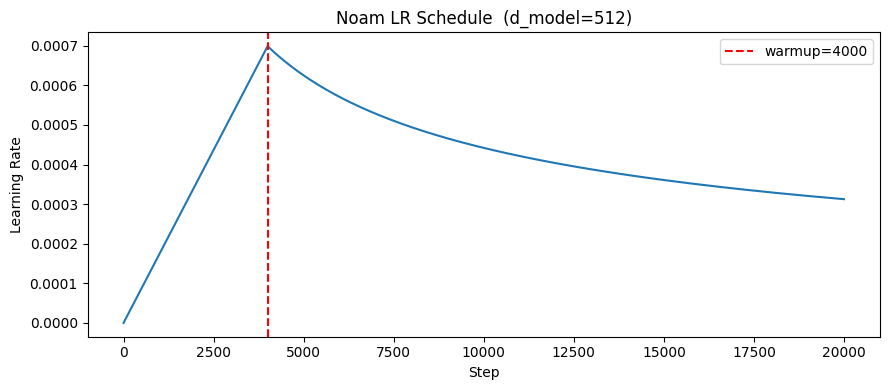

In [3]:
"""
Noam Learning Rate Scheduler
Reference: "Attention Is All You Need" (Vaswani et al., 2017)
           https://arxiv.org/abs/1706.03762

Formula:
    lrate = d_model^(-0.5) * min(step^(-0.5), step * warmup_steps^(-1.5))
"""

import torch
import torch.optim as optim
from torch.optim.lr_scheduler import LRScheduler

# ─────────────────────────────────────────────
# NoamScheduler implementation
# ─────────────────────────────────────────────


class NoamScheduler(LRScheduler):
    """
    Noam learning rate scheduler as described in "Attention Is All You Need".

    Applies a warm-up phase where LR increases linearly, followed by
    a decay phase where LR decreases proportional to the inverse square
    root of the step number.

    Args:
        optimizer (torch.optim.Optimizer): Wrapped optimizer.
        d_model          (int)  : Model dimensionality (embedding size).
        warmup_steps     (int)  : Number of warm-up steps before decay begins.
        last_epoch       (int)  : The index of the last epoch. Default: -1.
    """

    def __init__(
        self,
        optimizer: optim.Optimizer,
        d_model: int,
        warmup_steps: int,
        last_epoch: int = -1,
    ) -> None:
        if d_model <= 0:
            raise ValueError("d_model must be positive")
        if warmup_steps <= 0:
            raise ValueError("warmup_steps must be positive")

        self.d_model = d_model
        self.warmup_steps = warmup_steps
        super().__init__(optimizer, last_epoch=last_epoch)

    # ------------------------------------------------------------------
    def _get_lr_scale(self) -> float:
        """
        Compute the Noam scaling factor for the current step.

        Returns:
            float: The scalar multiplier applied to the base learning rate.

        Hint:
            step = self.last_epoch + 1            # avoid step=0
            scale = d_model^(-0.5) * min(step^(-0.5), step * warmup_steps^(-1.5))
        """
        step = max(self.last_epoch + 1, 1)
        return (self.d_model**-0.5) * min(
            step**-0.5,
            step * (self.warmup_steps**-1.5),
        )

    # ------------------------------------------------------------------
    def get_lr(self) -> list[float]:
        """
        Compute learning rates for every param group.

        Called internally by PyTorch's scheduler machinery each step.

        Returns:
            list[float]: New learning rate for each param group in the optimizer.

        Hint:
            Multiply each group's `base_lr` by the value from `_get_lr_scale()`.
            Access base learning rates via `self.base_lrs`.
        """
        scale = self._get_lr_scale()
        return [base_lr * scale for base_lr in self.base_lrs]


# ──────────────────────────────────────────────────────────────────────
# Helper — do NOT modify
# ──────────────────────────────────────────────────────────────────────


def get_lr_history(
    d_model: int,
    warmup_steps: int,
    total_steps: int,
) -> list[float]:
    """
    Simulate the LR trajectory of NoamScheduler for `total_steps` steps.

    Args:
        d_model      (int): Model dimensionality.
        warmup_steps (int): Warm-up steps.
        total_steps  (int): Number of steps to simulate.

    Returns:
        list[float]: LR value at each step (length == total_steps).
    """
    dummy_model = torch.nn.Linear(1, 1)
    optimizer = optim.Adam(dummy_model.parameters(), lr=1.0)
    scheduler = NoamScheduler(optimizer, d_model=d_model, warmup_steps=warmup_steps)

    history = []
    for _ in range(total_steps):
        history.append(optimizer.param_groups[0]["lr"])
        optimizer.step()
        scheduler.step()

    return history


# ──────────────────────────────────────────────────────────────────────
# Quick visual check — run:  python noam_lr_scheduler.py
# ──────────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    import matplotlib.pyplot as plt

    D_MODEL = 512
    WARMUP_STEPS = 4000
    TOTAL_STEPS = 20_000

    lrs = get_lr_history(D_MODEL, WARMUP_STEPS, TOTAL_STEPS)

    plt.figure(figsize=(9, 4))
    plt.plot(lrs)
    plt.axvline(
        WARMUP_STEPS, color="red", linestyle="--", label=f"warmup={WARMUP_STEPS}"
    )
    plt.xlabel("Step")
    plt.ylabel("Learning Rate")
    plt.title(f"Noam LR Schedule  (d_model={D_MODEL})")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Cell 4 — train.py

In [4]:
"""
Training, inference, BLEU evaluation, and checkpoint utilities for
DA6401 Assignment 3.
"""
print("Hi I am alive things are working")
import argparse
from collections import Counter
import math
import os
from pathlib import Path
import random
from typing import Optional

import gdown
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm



class LabelSmoothingLoss(nn.Module):
    """
    Label smoothing as in "Attention Is All You Need".
    """

    def __init__(self, vocab_size: int, pad_idx: int, smoothing: float = 0.1) -> None:
        super().__init__()
        if not 0.0 <= smoothing < 1.0:
            raise ValueError("smoothing must be in the range [0, 1)")
        if not 0 <= pad_idx < vocab_size:
            raise ValueError("pad_idx must be a valid vocabulary index")

        self.vocab_size = vocab_size
        self.pad_idx = pad_idx
        self.smoothing = smoothing
        self.confidence = 1.0 - smoothing
        self.criterion = nn.KLDivLoss(reduction="sum")

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        """
        Args:
            logits: shape [batch * tgt_len, vocab_size]
            target: shape [batch * tgt_len]
        """
        logits = logits.reshape(-1, self.vocab_size)
        target = target.reshape(-1)
        log_probs = F.log_softmax(logits, dim=-1)

        with torch.no_grad():
            true_dist = torch.zeros_like(log_probs)
            if self.vocab_size > 2:
                true_dist.fill_(self.smoothing / (self.vocab_size - 2))
            true_dist[:, self.pad_idx] = 0.0
            true_dist.scatter_(1, target.unsqueeze(1), self.confidence)
            true_dist[:, self.pad_idx] = 0.0
            true_dist.masked_fill_((target == self.pad_idx).unsqueeze(1), 0.0)

        token_count = (target != self.pad_idx).sum().clamp_min(1)
        return self.criterion(log_probs, true_dist) / token_count


def run_epoch(
    data_iter,
    model: Transformer,
    loss_fn: nn.Module,
    optimizer: Optional[torch.optim.Optimizer],
    scheduler=None,
    epoch_num: int = 0,
    is_train: bool = True,
    device: str = "cpu",
    step_state: Optional[dict] = None,
    max_train_steps: Optional[int] = None,
) -> tuple[float, float, float, float, bool]:
    """
    Run one epoch of teacher-forced training or validation.
    """
    model.train(is_train)
    total_loss = 0.0
    total_ce_loss = 0.0
    total_tokens = 0
    total_correct = 0
    total_confidence = 0.0
    stopped_early = False
    pad_idx = getattr(loss_fn, "pad_idx", 1)
    iterator = tqdm(
        data_iter,
        desc=f"{'train' if is_train else 'val'} {epoch_num}",
        leave=False,
        disable=_disable_tqdm(),
    )

    for src, tgt in iterator:
        src = src.to(device)
        tgt = tgt.to(device)
        tgt_input = tgt[:, :-1]
        tgt_output = tgt[:, 1:]
        src_mask = make_src_mask(src, pad_idx=pad_idx)
        tgt_mask = make_tgt_mask(tgt_input, pad_idx=pad_idx)

        if is_train:
            if optimizer is None:
                raise ValueError("optimizer is required when is_train=True")
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            logits = model(src, tgt_input, src_mask, tgt_mask)
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), tgt_output.reshape(-1))

        with torch.no_grad():
            flat_logits = logits.reshape(-1, logits.size(-1))
            flat_target = tgt_output.reshape(-1)
            correct, num_tokens = _token_accuracy(flat_logits, flat_target, pad_idx)
            confidence, confidence_tokens = _prediction_confidence(flat_logits, flat_target, pad_idx)
            ce_loss = F.cross_entropy(
                flat_logits,
                flat_target,
                ignore_index=pad_idx,
                reduction="sum",
            ).item()
            total_correct += correct
            total_confidence += confidence
            total_ce_loss += ce_loss

        if is_train:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            if scheduler is not None:
                scheduler.step()

            if step_state is not None:
                step_state["global_step"] = step_state.get("global_step", 0) + 1
                if max_train_steps is not None and step_state["global_step"] >= max_train_steps:
                    stopped_early = True
                    break

        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens
        iterator.set_postfix(
            loss=total_loss / max(total_tokens, 1),
            acc=total_correct / max(total_tokens, 1),
        )

        if stopped_early:
            break

    avg_loss = total_loss / max(total_tokens, 1)
    avg_ce_loss = total_ce_loss / max(total_tokens, 1)
    avg_accuracy = total_correct / max(total_tokens, 1)
    avg_confidence = total_confidence / max(total_tokens, 1)
    return avg_loss, avg_accuracy, avg_confidence, avg_ce_loss, stopped_early


def greedy_decode(
    model: Transformer,
    src: torch.Tensor,
    src_mask: torch.Tensor,
    max_len: int,
    start_symbol: int,
    end_symbol: int = 3,
    device: str = "cpu",
) -> torch.Tensor:
    """
    Generate a translation token-by-token using greedy decoding.
    """
    was_training = model.training
    model.eval()
    src = src.to(device)
    src_mask = src_mask.to(device)

    with torch.no_grad():
        memory = model.encode(src, src_mask)
        ys = torch.full((1, 1), start_symbol, dtype=torch.long, device=device)

        for _ in range(max_len - 1):
            tgt_mask = make_tgt_mask(ys, pad_idx=1).to(device)
            logits = model.decode(memory, src_mask, ys, tgt_mask)
            next_word = torch.argmax(logits[:, -1, :], dim=-1).item()
            ys = torch.cat(
                [ys, torch.tensor([[next_word]], dtype=torch.long, device=device)], dim=1
            )
            if next_word == end_symbol:
                break

    model.train(was_training)
    return ys


def _vocab_index(vocab, token: str, default: int) -> int:
    if hasattr(vocab, "stoi"):
        return int(vocab.stoi.get(token, default))
    try:
        return int(vocab[token])
    except Exception:
        return default


def _lookup_token(vocab, index: int) -> str:
    if hasattr(vocab, "lookup_token"):
        return vocab.lookup_token(index)
    if hasattr(vocab, "itos"):
        return vocab.itos[index]
    raise TypeError("tgt_vocab must expose lookup_token(index) or itos")


def _tokens_from_ids(vocab, ids: list[int], stop_at_eos: bool = True) -> list[str]:
    specials = {PAD_TOKEN, SOS_TOKEN, EOS_TOKEN}
    tokens = []
    for index in ids:
        token = _lookup_token(vocab, int(index))
        if stop_at_eos and token == EOS_TOKEN:
            break
        if token not in specials:
            tokens.append(token)
    return tokens


def _ngrams(tokens: list[str], n: int) -> Counter:
    return Counter(tuple(tokens[i : i + n]) for i in range(len(tokens) - n + 1))


def _corpus_bleu(hypotheses: list[list[str]], references: list[list[str]]) -> float:
    if not hypotheses:
        return 0.0

    hyp_len = sum(len(hyp) for hyp in hypotheses)
    ref_len = sum(len(ref) for ref in references)
    if hyp_len == 0:
        return 0.0

    precisions = []
    for n in range(1, 5):
        matches = 0
        total = 0
        for hyp, ref in zip(hypotheses, references):
            hyp_ngrams = _ngrams(hyp, n)
            ref_ngrams = _ngrams(ref, n)
            total += sum(hyp_ngrams.values())
            for ngram, count in hyp_ngrams.items():
                matches += min(count, ref_ngrams.get(ngram, 0))
        if total == 0 or matches == 0:
            precisions.append(0.0)
        else:
            precisions.append(matches / total)

    if min(precisions) == 0.0:
        return 0.0

    brevity_penalty = 1.0 if hyp_len > ref_len else math.exp(1.0 - ref_len / hyp_len)
    bleu = brevity_penalty * math.exp(sum(math.log(p) for p in precisions) / 4.0)
    return 100.0 * bleu


def evaluate_bleu(
    model: Transformer,
    test_dataloader: DataLoader,
    tgt_vocab,
    device: str = "cpu",
    max_len: int = 100,
) -> float:
    """
    Evaluate translation quality with corpus-level BLEU score.
    """
    if hasattr(model, "_ensure_checkpoint_loaded"):
        model._ensure_checkpoint_loaded()

    pad_idx = _vocab_index(tgt_vocab, PAD_TOKEN, 1)
    sos_idx = _vocab_index(tgt_vocab, SOS_TOKEN, 2)
    eos_idx = _vocab_index(tgt_vocab, EOS_TOKEN, 3)
    hypotheses = []
    references = []
    was_training = model.training
    model.eval()

    for src, tgt in tqdm(test_dataloader, desc="bleu", leave=False, disable=_disable_tqdm()):
        for row_idx in range(src.size(0)):
            src_row = src[row_idx : row_idx + 1].to(device)
            src_mask = make_src_mask(src_row, pad_idx=pad_idx)
            pred = greedy_decode(
                model,
                src_row,
                src_mask,
                max_len=max_len,
                start_symbol=sos_idx,
                end_symbol=eos_idx,
                device=device,
            )
            hypotheses.append(_tokens_from_ids(tgt_vocab, pred.squeeze(0).tolist()))
            references.append(_tokens_from_ids(tgt_vocab, tgt[row_idx].tolist()))

    model.train(was_training)
    return _corpus_bleu(hypotheses, references)


def save_checkpoint(
    model: Transformer,
    optimizer: torch.optim.Optimizer,
    scheduler,
    epoch: int,
    path: str = "checkpoint.pt",
) -> None:
    """
    Save model + optimiser + scheduler state to disk.
    """
    checkpoint_path = Path(path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model_config = model.get_config() if hasattr(model, "get_config") else {
        "src_vocab_size": model.src_vocab_size,
        "tgt_vocab_size": model.tgt_vocab_size,
        "d_model": model.d_model,
        "N": model.N,
        "num_heads": model.num_heads,
        "d_ff": model.d_ff,
        "dropout": model.dropout,
    }

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict() if optimizer is not None else None,
            "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
            "model_config": model_config,
        },
        checkpoint_path,
    )


def load_checkpoint(
    path: str,
    model: Transformer,
    optimizer: Optional[torch.optim.Optimizer] = None,
    scheduler=None,
) -> int:
    """
    Restore model and optionally optimizer/scheduler state from disk.
    """
    checkpoint_path = Path(path)
    if not checkpoint_path.exists():
        checkpoint_path = next(
            (candidate for candidate in _checkpoint_candidates() if candidate.exists()),
            DEFAULT_CHECKPOINT_PATH,
        )

    try:
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    except TypeError:
        checkpoint = torch.load(checkpoint_path, map_location="cpu")
    model.load_state_dict(checkpoint["model_state_dict"])
    if hasattr(model, "_inference_checkpoint_loaded"):
        model._inference_checkpoint_loaded = True

    optimizer_state = checkpoint.get("optimizer_state_dict")
    if optimizer is not None and optimizer_state is not None:
        optimizer.load_state_dict(optimizer_state)

    scheduler_state = checkpoint.get("scheduler_state_dict")
    if scheduler is not None and scheduler_state is not None:
        scheduler.load_state_dict(scheduler_state)

    return int(checkpoint["epoch"])


def download_checkpoint_from_gdrive(
    file_id: str = "1rXyhzh_9ozSHLu0uPwi_R7U0Tgqoi73n",
    output_path: str = "checkpoints/best_bleu_checkpoint.pt",
) -> None:
    """
    Download a checkpoint file from Google Drive using gdown.
    
    Args:
        file_id: The Google Drive file ID
        output_path: The local path to save the file
    """
    output_dir = Path(output_path).parent
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Check if file already exists
    if Path(output_path).exists():
        print(f"Checkpoint already exists at {output_path}. Skipping download.")
        return
    
    print(f"Downloading checkpoint from Google Drive to {output_path}...")
    url = f"https://drive.google.com/uc?id={file_id}"
    try:
        gdown.download(url, output_path, quiet=False)
        print(f"Successfully downloaded checkpoint to {output_path}")
    except Exception as e:
        print(f"Error downloading checkpoint: {e}")
        print(f"Please manually download from: https://drive.google.com/file/d/{file_id}/view?usp=sharing")
        raise


def _env(name: str, default, cast):
    value = os.getenv(name)
    if value is None or value == "":
        return default
    return cast(value)


def _disable_tqdm() -> bool:
    return os.getenv("DISABLE_TQDM", "false").lower() in {"1", "true", "yes"}


def _set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _parse_cli_args() -> dict:
    parser = argparse.ArgumentParser(description="Train the DA6401 assignment 3 Transformer")
    parser.add_argument("--task-name", default=None)
    parser.add_argument("--num-epochs", default=None, type=int)
    parser.add_argument("--checkpoint-dir", default=None)
    parser.add_argument("--best-checkpoint", default=None)
    parser.add_argument("--resume-checkpoint", default=None)
    parser.add_argument("--lr-strategy", default=None)
    parser.add_argument("--learning-rate", default=None, type=float)
    parser.add_argument("--label-smoothing", dest="smoothing", default=None, type=float)
    parser.add_argument("--positional-encoding", default=None)
    parser.add_argument("--no-attention-scaling", action="store_true")
    parser.add_argument("--max-train-steps", default=None, type=int)
    args, _ = parser.parse_known_args()   # ← was parser.parse_args()
    return {key: value for key, value in vars(args).items() if value is not None}



def _token_accuracy(logits: torch.Tensor, target: torch.Tensor, pad_idx: int) -> tuple[int, int]:
    predictions = logits.argmax(dim=-1)
    non_pad = target != pad_idx
    correct = ((predictions == target) & non_pad).sum().item()
    total = non_pad.sum().item()
    return correct, total


def _prediction_confidence(logits: torch.Tensor, target: torch.Tensor, pad_idx: int) -> tuple[float, int]:
    non_pad = target != pad_idx
    token_count = non_pad.sum().item()
    if token_count == 0:
        return 0.0, 0

    probs = F.softmax(logits, dim=-1)
    chosen = probs.gather(-1, target.unsqueeze(-1)).squeeze(-1)
    confidence = chosen.masked_select(non_pad).sum().item()
    return confidence, token_count


def run_training_experiment(overrides: Optional[dict] = None) -> None:
    """
    Run the full Multi30k German-to-English training experiment.
    """
    overrides = overrides or {}
    config = {
        "seed": _env("SEED", 42, int),
        "batch_size": _env("BATCH_SIZE", 32, int),
        "num_epochs": overrides.get("num_epochs", _env("NUM_EPOCHS", 20, int)),
        "d_model": _env("D_MODEL", 256, int),
        "N": _env("NUM_LAYERS", 3, int),
        "num_heads": _env("NUM_HEADS", 8, int),
        "d_ff": _env("D_FF", 1024, int),
        "dropout": _env("DROPOUT", 0.1, float),
        "smoothing": overrides.get("smoothing", _env("LABEL_SMOOTHING", 0.1, float)),
        "warmup_steps": _env("WARMUP_STEPS", 4000, int),
        "min_freq": _env("MIN_FREQ", 2, int),
        "max_len": _env("MAX_LEN", 100, int),
        "num_workers": _env("NUM_WORKERS", 0, int),
        "checkpoint_dir": overrides.get("checkpoint_dir", os.getenv("CHECKPOINT_DIR", "checkpoints")),
        "best_checkpoint": overrides.get("best_checkpoint", os.getenv("BEST_CHECKPOINT", "checkpoint.pt")),
        "resume_checkpoint": overrides.get("resume_checkpoint", os.getenv("RESUME_CHECKPOINT", "")),
        "extra_epochs": _env("EXTRA_EPOCHS", 0, int),
        "task_name": overrides.get("task_name", _env("TASK_NAME", "baseline", str)),
        "lr_strategy": overrides.get("lr_strategy", os.getenv("LR_STRATEGY", "noam")),
        "learning_rate": overrides.get("learning_rate", _env("LEARNING_RATE", 1e-4, float)),
        "attention_scaling_label": "scaled" if not overrides.get("no_attention_scaling", False) else "no_scale",
        "positional_encoding": overrides.get(
            "positional_encoding", os.getenv("POSITIONAL_ENCODING", "sinusoidal")
        ),
        "use_attention_scaling": not overrides.get("no_attention_scaling", False),
        "max_train_steps": overrides.get("max_train_steps", _env("MAX_TRAIN_STEPS", 0, int)),
    }
    _set_seed(config["seed"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


    train_dataset = Multi30kDataset(
        "train", min_freq=config["min_freq"], max_len=config["max_len"]
    )
    val_dataset = Multi30kDataset(
        "validation",
        src_vocab=train_dataset.src_vocab,
        tgt_vocab=train_dataset.tgt_vocab,
        min_freq=config["min_freq"],
        max_len=config["max_len"],
    )
    test_dataset = Multi30kDataset(
        "test",
        src_vocab=train_dataset.src_vocab,
        tgt_vocab=train_dataset.tgt_vocab,
        min_freq=config["min_freq"],
        max_len=config["max_len"],
    )

    loader_kwargs = {
        "batch_size": config["batch_size"],
        "num_workers": config["num_workers"],
        "pin_memory": device.type == "cuda",
    }
    train_loader = DataLoader(
        train_dataset,
        shuffle=True,
        collate_fn=train_dataset.collate_fn,
        **loader_kwargs,
    )
    val_loader = DataLoader(
        val_dataset,
        shuffle=False,
        collate_fn=val_dataset.collate_fn,
        **loader_kwargs,
    )
    test_loader = DataLoader(
        test_dataset,
        shuffle=False,
        collate_fn=test_dataset.collate_fn,
        **loader_kwargs,
    )

    model = Transformer(
        src_vocab_size=len(train_dataset.src_vocab),
        tgt_vocab_size=len(train_dataset.tgt_vocab),
        d_model=config["d_model"],
        N=config["N"],
        num_heads=config["num_heads"],
        d_ff=config["d_ff"],
        dropout=config["dropout"],
        use_learned_positional_encoding=config["positional_encoding"].lower() == "learned",
        use_attention_scaling=config["use_attention_scaling"],
    ).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1.0 if config["lr_strategy"].lower() == "noam" else config["learning_rate"],
        betas=(0.9, 0.98),
        eps=1e-9,
    )
    scheduler = None
    if config["lr_strategy"].lower() == "noam":
        scheduler = NoamScheduler(
            optimizer,
            d_model=config["d_model"],
            warmup_steps=config["warmup_steps"],
        )
    loss_fn = LabelSmoothingLoss(
        vocab_size=len(train_dataset.tgt_vocab),
        pad_idx=train_dataset.tgt_pad_idx,
        smoothing=config["smoothing"],
    )

    checkpoint_dir = Path(config["checkpoint_dir"])
    latest_path = checkpoint_dir / "latest_checkpoint.pt"
    best_path = Path(config["best_checkpoint"])
    best_val_loss = float("inf")
    start_epoch = 1
    step_state = {"global_step": 0}

    # Download checkpoint from Google Drive if it doesn't exist
    best_checkpoint_path = str(best_path)
    download_checkpoint_from_gdrive(
        file_id="1rXyhzh_9ozSHLu0uPwi_R7U0Tgqoi73n",
        output_path=best_checkpoint_path,
    )

    try:
        if config["resume_checkpoint"]:
            resume_path = Path(config["resume_checkpoint"])
            if resume_path.exists():
                start_epoch = load_checkpoint(str(resume_path), model, optimizer, scheduler) + 1
                print(f"resumed_from={resume_path} start_epoch={start_epoch}")
            else:
                raise FileNotFoundError(f"resume checkpoint not found: {resume_path}")

        end_epoch = start_epoch + config["num_epochs"] + config["extra_epochs"] - 1

        for epoch in range(start_epoch, end_epoch + 1):
            (
                train_loss,
                train_accuracy,
                train_confidence,
                train_ce_loss,
                stopped_early,
            ) = run_epoch(
                train_loader,
                model,
                loss_fn,
                optimizer,
                scheduler,
                epoch_num=epoch,
                is_train=True,
                device=str(device),
                step_state=step_state,
                max_train_steps=config["max_train_steps"] or None,
            )
            if stopped_early:
                print(f"stopped_early=1 global_step={step_state['global_step']}")
                return
            val_loss, val_accuracy, val_confidence, val_ce_loss, _ = run_epoch(
                val_loader,
                model,
                loss_fn,
                optimizer=None,
                scheduler=None,
                epoch_num=epoch,
                is_train=False,
                device=str(device),
            )

            save_checkpoint(model, optimizer, scheduler, epoch, str(latest_path))
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                save_checkpoint(model, optimizer, scheduler, epoch, str(best_path))

            lr = scheduler.get_last_lr()[0] if scheduler is not None else optimizer.param_groups[0]["lr"]

            print(
                f"epoch={epoch} train_loss={train_loss:.4f} "
                f"val_loss={val_loss:.4f} best_val_loss={best_val_loss:.4f}"
            )

        load_checkpoint(str(best_path), model, optimizer=None, scheduler=None)
        val_bleu = evaluate_bleu(
            model,
            val_loader,
            train_dataset.tgt_vocab,
            device=str(device),
            max_len=config["max_len"],
        )
        print(f"val_bleu={val_bleu:.2f}")
        test_bleu = evaluate_bleu(
            model,
            test_loader,
            train_dataset.tgt_vocab,
            device=str(device),
            max_len=config["max_len"],
        )
        print(f"test_bleu={test_bleu:.2f}")
    finally:
        pass

Hi I am alive things are working


## Cell 5 — Install, configure, and train

After this cell finishes the best checkpoint is at `/kaggle/working/checkpoints/best_bleu_checkpoint.pt`.
Download it, upload to Google Drive, copy the file-id into `model.py` line 28 (`DEFAULT_CHECKPOINT_FILE_ID`), then push to GitHub.

In [5]:
import subprocess, sys

# ── install dependencies ───────────────────────────────────────────────
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'datasets', 'spacy', 'tqdm', 'gdown'], check=True)
subprocess.run([sys.executable, '-m', 'spacy', 'download', 'de_core_news_sm', '-q'], check=False)
subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm',  '-q'], check=False)

# ── config ─────────────────────────────────────────────────────────────
import os
os.environ['SEED']           = '42'
os.environ['BATCH_SIZE']     = '128'
os.environ['NUM_EPOCHS']     = '100'
os.environ['D_MODEL']        = '256'
os.environ['NUM_LAYERS']     = '5'
os.environ['NUM_HEADS']      = '16'
os.environ['D_FF']           = '1024'
os.environ['DROPOUT']        = '0.1'
os.environ['LABEL_SMOOTHING']= '0.1'
os.environ['WARMUP_STEPS']   = '4000'
os.environ['MIN_FREQ']       = '2'
os.environ['MAX_LEN']        = '100'
os.environ['NUM_WORKERS']    = '2'
os.environ['LR_STRATEGY']    = 'noam'
os.environ['CHECKPOINT_DIR'] = 'checkpoints'
os.environ['BEST_CHECKPOINT']= 'checkpoints/best_bleu_checkpoint.pt'

# ── run training ───────────────────────────────────────────────────────
sys.path.insert(0, '/kaggle/working')
run_training_experiment()

print()
print('='*55)
print('  DONE — checkpoint saved to:')
print('  /kaggle/working/checkpoints/best_bleu_checkpoint.pt')
print()
print('  Next steps:')
print('  1. Go to Kaggle Output tab and download the .pt file')
print('  2. Upload it to Google Drive and copy the file-id')
print('     (the long string in the share link after /d/)')
print('  3. Open model.py line 28 and set:')
print('     DEFAULT_CHECKPOINT_FILE_ID = "<your_file_id>"')
print('  4. git commit && git push && submit on Gradescope')
print('='*55)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 69.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 71.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


README.md: 0.00B [00:00, ?B/s]

train.jsonl: 0.00B [00:00, ?B/s]

val.jsonl: 0.00B [00:00, ?B/s]

test.jsonl: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/29000 [00:00<?, ? examples/s]

... (135 outputs left out)

bleu:   0%|          | 0/8 [00:00<?, ?it/s]

val_bleu=38.25


bleu:   0%|          | 0/8 [00:00<?, ?it/s]

test_bleu=38.46

  DONE — checkpoint saved to:
  /kaggle/working/checkpoints/best_bleu_checkpoint.pt

  Next steps:
  1. Go to Kaggle Output tab and download the .pt file
  2. Upload it to Google Drive and copy the file-id
     (the long string in the share link after /d/)
  3. Open model.py line 28 and set:
     DEFAULT_CHECKPOINT_FILE_ID = "<your_file_id>"
  4. git commit && git push && submit on Gradescope
